# P3.08 — A surcharge on vacant homes: revenue and bite

**Question:** RQ7.6 (what is the fiscal impact of alternative property-tax reforms, including vacant-property incentives?).
Builds on `p2_16` (excess vacancy) and `p3_05` (IMI is municipal revenue).

CIMI art. 112(3) lets a council raise the urban IMI rate on buildings vacant for over a year; the multiple applied in practice is
three (54 councils did so for the 2017 tax, hitting 8,239 owners, according to the press; the current rules after Lei 56/2023 are not
checked here). The census counts vacant homes but not the legal classification, so the share of the excess that a council could
classify as vacant is varied, not assumed. The estimate is **accounting only**: it keeps owners where they are. The point of such a
surcharge is that owners let, sell or repair instead, which lowers its revenue, so the figures are an upper bound on revenue and say
nothing about how many homes return. What they do show is how large the surcharge is next to what the owner forgoes.

Three steps. (1) The IMI of a typical dwelling in each municipality is built from the price per m², the census area, the taxable
share and the urban rate, then scaled so that all dwellings add up to the national-accounts IMI of 2024. (2) The surcharge is the
extra two times that bill on the excess vacant homes (above 5% of the stock). (3) Its bite is the extra tax as a share of a year's
median new-lease rent.

In [1]:
import pandas as pd

from pthousing.analysis import revenue, supply, vacancy
from pthousing.config import IMI_TAXABLE_SHARE, PROCESSED, VACANT_IMI_MULTIPLE
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
YEAR = 2024
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
tax = interim.read("eurostat_property_tax").set_index("year")
tab = vacancy.table(supply.read_stock())
excess = vacancy.excess(tab["vacant_2021_n"], tab["dwellings_2021_n"])
national = float(tax.loc[YEAR, "imi_revenue_eur_m"])

## Step 1 — The IMI of a typical dwelling
The bottom-up bill is 37% above the national accounts: the price of homes sold overstates the assessed value of the stock (old
homes are assessed far below market, some are exempt). The scale factor brings it to the national total, equivalent to an average
taxable share of 44% of the price instead of 60%. IMI also covers commercial and rustic property, so attributing all of it to dwellings
is an upper bound for their bill.

In [2]:
per_dwelling = revenue.imi_per_dwelling(panel, YEAR)
scale = revenue.calibration(per_dwelling, tab["dwellings_2021_n"], national)
unit = per_dwelling * scale
print(
    f"bottom-up unweighted mean {per_dwelling.mean():.0f} EUR, scale {scale:.3f} (taxable share {IMI_TAXABLE_SHARE * scale:.2f} instead of {IMI_TAXABLE_SHARE})"
)
print(unit.describe().round(0).to_string())

bottom-up unweighted mean 250 EUR, scale 0.731 (taxable share 0.44 instead of 0.6)
count    296.0
mean     183.0
std      115.0
min       32.0
25%       93.0
50%      158.0
75%      246.0
max      641.0


## Step 2 — Revenue of the surcharge
Every municipality, and only the third with the highest 2024 price-to-income (where a pressure-zone rule would apply).

In [3]:
pti = panel[panel["year"] == YEAR].set_index("muni_code")["pti_years"].dropna()
pressured = pti.index[pd.qcut(pti, 3, labels=False) == 2]
shares = (0.25, 0.5, 1.0)
table = pd.DataFrame(
    {
        "all_eur_m": [
            revenue.vacant_surcharge(per_dwelling, excess, s, scale).sum() / 1e6 for s in shares
        ],
        "pressured_eur_m": [
            revenue.vacant_surcharge(per_dwelling, excess, s, scale)[
                excess.index.isin(pressured)
            ].sum()
            / 1e6
            for s in shares
        ],
    },
    index=pd.Index(shares, name="classified_vacant_share"),
)
table["all_pct_of_imi"] = 100 * table["all_eur_m"] / national
table["pressured_pct_of_imi"] = 100 * table["pressured_eur_m"] / national
style.save_table(table.round(1).reset_index(), "p3", "vacant_surcharge_revenue")
table.round(1)

,all_eur_m,pressured_eur_m,all_pct_of_imi,pressured_pct_of_imi
classified_vacant_share,,,,
0.25,55.3,42.8,3.3,2.6
0.50,110.6,85.7,6.6,5.1
1.00,221.2,171.4,13.2,10.2


## Step 3 — How much does it weigh on the owner?
Extra yearly IMI (the multiple minus one, times the typical bill) over the yearly rent of the median new lease for a home of the
municipality's average area, in the 206 municipalities with a published rent. A typical home yields about 20 times the extra tax (9 to 55 times across municipalities).

,extra_imi_eur,surcharge_share_of_rent_pct
count,296.0,206.0
mean,365.2,5.1
std,229.7,1.4
min,64.9,1.8
25%,186.6,4.1
50%,316.6,5.1
75%,491.6,5.9
max,1281.4,10.7


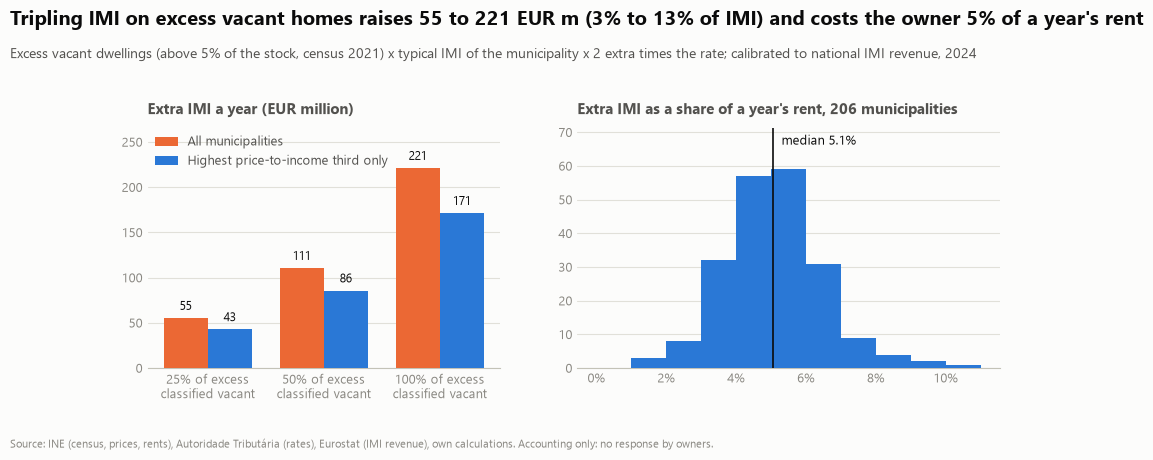

In [4]:
bite = revenue.surcharge_bite(per_dwelling, scale, panel, YEAR)
extra = (VACANT_IMI_MULTIPLE - 1) * unit
fig = charts.vacant_surcharge(table, bite, national)
style.save_fig(fig, "p3", "vacant_surcharge")
summary = pd.DataFrame(
    {
        "extra_imi_eur": extra.describe(),
        "surcharge_share_of_rent_pct": (100 * bite).describe(),
    }
).round(1)
style.save_table(summary.reset_index(names="statistic"), "p3", "vacant_surcharge_bite")
summary

## Key numbers

In [5]:
print(f"national IMI 2024 {national:,.0f} EUR m; excess vacant homes {excess.sum():,.0f}")
for s, r in table.iterrows():
    print(
        f"  {s:.0%} classified vacant: {r.all_eur_m:,.0f} EUR m ({r.all_pct_of_imi:.1f}% of IMI); highest price-to-income third {r.pressured_eur_m:,.0f} EUR m ({r.pressured_pct_of_imi:.1f}%)"
    )
print(
    f"median extra IMI per home {extra.median():,.0f} EUR a year (90th percentile {extra.quantile(0.9):,.0f}); "
    f"{100 * bite.median():.1f}% of a year's rent (median), maximum {100 * bite.max():.0f}% (n {bite.notna().sum()})"
)

national IMI 2024 1,677 EUR m; excess vacant homes 424,681
  25% classified vacant: 55 EUR m (3.3% of IMI); highest price-to-income third 43 EUR m (2.6%)
  50% classified vacant: 111 EUR m (6.6% of IMI); highest price-to-income third 86 EUR m (5.1%)
  100% classified vacant: 221 EUR m (13.2% of IMI); highest price-to-income third 171 EUR m (10.2%)
median extra IMI per home 317 EUR a year (90th percentile 691); 5.1% of a year's rent (median), maximum 11% (n 206)
